# 3D Helmholtz PFDM — linear-algebra scaling for the multi-frequency \((0,2)^3\) experiment

This notebook benchmarks the same exact-boundary PFDM system used in `main(3).ipynb`:

\[
\Omega=(0,2)^3,
\]

\[
u^\star(x,y,z)
=
\sin(\pi x)\sin(\pi y)\sin(\pi z)
+
0.3\sin(3\pi x)\sin(3\pi y)\sin(2\pi z),
\]

with the numerics-informed hyperparameters selected in the \(N_x=7\) experiment:

\[
\nu=1.5,\qquad
\ell=0.5,\qquad
\sigma_f=1.20333,\qquad
C=10321.4,\qquad
\tau=2,\qquad
k=1.
\]

We compare only:

- Cholesky (direct),
- Jacobi-PCG with dense covariance,
- Jacobi-PCG with BTTTB/3D-FFT covariance matvec.


In [1]:
using LinearAlgebra
using SparseArrays
using FFTW
using SpecialFunctions
using IterativeSolvers
using LinearMaps
using Plots
using Statistics
using Printf


In [2]:
# 3次元 Matérnカーネル（入力 x1, x2 ∈ R³）
function matern_kernel_3d(x1, x2; ν=1.5, ℓ=1.0, σf=1.0)
    r = sqrt(sum((x1 .- x2).^2))
    r == 0 && return σf^2
    z = sqrt(2ν) * r / ℓ
    if ν == 0.5
        return σf^2 * exp(-z)
    elseif ν == 1.5
        return σf^2 * (1 + z) * exp(-z)
    elseif ν == 2.5
        return σf^2 * (1 + z + z^2/3) * exp(-z)
    else
        return σf^2 * (2^(1-ν)/gamma(ν)) * z^ν * besselk(ν, z)
    end
end

# 3D observation matrix on the FULL grid, including boundaries.
#
# Boundary rows: u = 0 exactly  -> identity row
# Interior rows: (-Delta_h + k^2 I)u = f
#
# This is the direct 3D analogue of the 1D construction
#   Sigma_diag = [0, interior noise..., 0].
function build_H_3d_helmholtz_full(Nx, h, k)
    # Nx = number of INTERIOR points per coordinate direction.
    nside = Nx + 2
    Nall  = nside^3

    index(i,j,l) = i + (j-1)*nside + (l-1)*nside^2

    rows = Int[]
    cols = Int[]
    vals = Float64[]
    is_boundary = falses(Nall)

    for l in 1:nside, j in 1:nside, i in 1:nside
        q = index(i,j,l)

        bdry = (i == 1 || i == nside ||
                j == 1 || j == nside ||
                l == 1 || l == nside)

        is_boundary[q] = bdry

        if bdry
            # Exact homogeneous Dirichlet condition.
            push!(rows,q); push!(cols,q); push!(vals,1.0)
        else
            # Helmholtz PDE row on an interior point.
            push!(rows,q); push!(cols,q); push!(vals,6.0/h^2 + k^2)
            push!(rows,q); push!(cols,index(i-1,j,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i+1,j,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j-1,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j+1,l)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j,l-1)); push!(vals,-1.0/h^2)
            push!(rows,q); push!(cols,index(i,j,l+1)); push!(vals,-1.0/h^2)
        end
    end

    H = sparse(rows,cols,vals,Nall,Nall)
    return H, is_boundary
end

# Observation vector on the full grid:
# boundary -> 0, interior -> f.
function make_y_3d_full(xfull, k, is_boundary)
    y = zeros(length(xfull))
    for q in eachindex(xfull)
        if !is_boundary[q]
            x,yq,z = xfull[q]
            y[q] = f_func(x,yq,z,k)
        end
    end
    return y
end

# BTTTB セットアップ: 3D循環埋め込み + 3D FFT
function btttb_fft_setup(k_col_arr, Nx, Ny, Nz)
    # k_col_arr[i,j,l] = k(x1, x_{i,j,l}) for i in 1:Nx, j in 1:Ny, l in 1:Nz
    C = zeros(2Nx, 2Ny, 2Nz)
    C[1:Nx, 1:Ny, 1:Nz] .= k_col_arr
    # x方向の折り返し
    Nx > 1 && (C[Nx+2:2Nx, 1:Ny, 1:Nz] .= k_col_arr[Nx:-1:2, :, :])
    # y方向の折り返し
    Ny > 1 && (C[1:Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[:, Ny:-1:2, :])
    # z方向の折り返し
    Nz > 1 && (C[1:Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[:, :, Nz:-1:2])
    # xy折り返し
    Nx > 1 && Ny > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, 1:Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, :])
    # xz折り返し
    Nx > 1 && Nz > 1 && (C[Nx+2:2Nx, 1:Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, :, Nz:-1:2])
    # yz折り返し
    Ny > 1 && Nz > 1 && (C[1:Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[:, Ny:-1:2, Nz:-1:2])
    # xyz折り返し
    Nx > 1 && Ny > 1 && Nz > 1 && (C[Nx+2:2Nx, Ny+2:2Ny, Nz+2:2Nz] .= k_col_arr[Nx:-1:2, Ny:-1:2, Nz:-1:2])
    return fft(fft(fft(C, 1), 2), 3)
end

function btttb_matvec(k_fft3, v, Nx, Ny, Nz)
    V     = reshape(v, Nx, Ny, Nz)
    V_pad = zeros(2Nx, 2Ny, 2Nz)
    V_pad[1:Nx, 1:Ny, 1:Nz] .= V
    result = real.(ifft(ifft(ifft(
        fft(fft(fft(V_pad, 1), 2), 3) .* k_fft3,
    1), 2), 3))
    return vec(result[1:Nx, 1:Ny, 1:Nz])
end

# 真の解・右辺: -Δu + k^2*u = f
#
# Multi-frequency manufactured solution:
#   u1 = sin(pi x) sin(pi y) sin(pi z)
#   u2 = sin(3pi x) sin(3pi y) sin(2pi z)
#
# -Δ u1 = 3 pi^2 u1
# -Δ u2 = (3^2+3^2+2^2) pi^2 u2 = 22 pi^2 u2
#
# Hence f is NOT proportional to u.

const alpha_hf = 0.3

function u_exact(x, y, z, k)
    u1 =
        sin(pi*x) *
        sin(pi*y) *
        sin(pi*z)

    u2 =
        sin(3pi*x) *
        sin(3pi*y) *
        sin(2pi*z)

    return u1 + alpha_hf*u2
end

function f_func(x, y, z, k)
    u1 =
        sin(pi*x) *
        sin(pi*y) *
        sin(pi*z)

    u2 =
        sin(3pi*x) *
        sin(3pi*y) *
        sin(2pi*z)

    return (3pi^2 + k^2)*u1 +
           alpha_hf*(22pi^2 + k^2)*u2
end


f_func (generic function with 1 method)

In [3]:
# ============================================================
# Jacobi diagonal for the exact-boundary full-grid system
#
# A = H K H' + Sigma + jitter I
# ============================================================

function exact_boundary_jacobi_diag(
    Nx,
    h,
    k_wave,
    is_boundary;
    ν,
    ℓ,
    σf,
    C,
    τ,
    jitter=1e-10
)

    nside = Nx + 2
    N = nside^3

    # Boundary row is identity: H_i = e_i'
    diag_boundary =
        σf^2 + jitter

    # Interior 7-point Helmholtz stencil
    c0 = 6.0/h^2 + k_wave^2
    c1 = -1.0/h^2

    coeffs = [
        c0,
        c1, c1,
        c1, c1,
        c1, c1
    ]

    pts = [
        [0.0,  0.0,  0.0],
        [-h,   0.0,  0.0],
        [ h,   0.0,  0.0],
        [0.0,  -h,   0.0],
        [0.0,   h,   0.0],
        [0.0,  0.0,  -h],
        [0.0,  0.0,   h]
    ]

    Kloc = [
        matern_kernel_3d(
            pts[a],
            pts[b];
            ν=ν,
            ℓ=ℓ,
            σf=σf
        )
        for a in 1:7,
            b in 1:7
    ]

    noise_var =
        C * h^(2τ)

    diag_interior =
        dot(
            coeffs,
            Kloc * coeffs
        ) +
        noise_var +
        jitter

    diagA = [
        is_boundary[q] ?
        diag_boundary :
        diag_interior
        for q in 1:N
    ]

    return diagA
end


exact_boundary_jacobi_diag (generic function with 1 method)

## Fixed benchmark parameters

The benchmark does **not** re-tune hyperparameters as \(N_x\) changes.
It uses the values selected by the proposed calibration in `main(3).ipynb`
at \(N_x=7\):

\[
(\ell,\sigma_f,C)=(0.5,1.20333,10321.4).
\]

Thus the timing experiment isolates linear-algebra scaling under the
actual parameter regime used by the PFDM experiment.


In [ ]:
# ============================================================
# Exact-boundary linear algebra benchmark
# with dense/FFT CG and Jacobi-preconditioned variants
# ============================================================

ν      = 1.5
ℓ      = 0.5
σf     = 1.20333
C      = 10321.4
τ      = 2
k_wave = 1.0
L_domain = 2.0

dense_max_N = 70000

grid_sizes = [
    3, 4, 5, 6,
    8, 10, 12, 15, 18, 20, 23, 25, 28, 30
]

results = NamedTuple[]

println("===========================================================")
println("Exact-boundary multi-frequency benchmark on (0,2)^3")
println("Cholesky vs PCG dense vs PCG FFT-based")
println("===========================================================")
@printf("nu      = %.6g\n", ν)
@printf("ell     = %.6g\n", ℓ)
@printf("sigma_f = %.6g\n", σf)
@printf("C       = %.6g\n", C)
@printf("tau     = %d\n", τ)
println()

for Nx in grid_sizes

    h = L_domain / (Nx + 1)
    nside = Nx + 2
    N = nside^3

    g = collect(
        range(
            0.0,
            L_domain,
            length=nside
        )
    )

    X_all = [
        [x,y,z]
        for z in g
        for y in g
        for x in g
    ]

    H, is_boundary =
        build_H_3d_helmholtz_full(
            Nx,
            h,
            k_wave
        )

    b_vec =
        make_y_3d_full(
            X_all,
            k_wave,
            is_boundary
        )

    u_true = [
        u_exact(
            x,
            y,
            z,
            k_wave
        )
        for z in g
        for y in g
        for x in g
    ]

    noise_var =
        C * h^(2τ)

    Sigma_diag = [
        is_boundary[q] ?
        0.0 :
        noise_var
        for q in 1:N
    ]

    jitter = 1e-10

    # --------------------------------------------------------
    # FFT covariance setup
    # --------------------------------------------------------
    k_col_arr = [
        matern_kernel_3d(
            [g[i],g[j],g[l]],
            [g[1],g[1],g[1]];
            ν=ν,
            ℓ=ℓ,
            σf=σf
        )
        for i in 1:nside,
            j in 1:nside,
            l in 1:nside
    ]

    k_fft3 =
        btttb_fft_setup(
            k_col_arr,
            nside,
            nside,
            nside
        )

    # --------------------------------------------------------
    # Matrix-free A
    # --------------------------------------------------------
    A_map = LinearMap(
        v -> begin
            w1 = H' * v
            w2 = btttb_matvec(
                k_fft3,
                w1,
                nside,
                nside,
                nside
            )
            w3 = H * w2
            w3 .+
            Sigma_diag .* v .+
            jitter .* v
        end,
        N;
        issymmetric=true,
        isposdef=true
    )

    # --------------------------------------------------------
    # Jacobi preconditioner
    # --------------------------------------------------------
    diagA =
        exact_boundary_jacobi_diag(
            Nx,
            h,
            k_wave,
            is_boundary;
            ν=ν,
            ℓ=ℓ,
            σf=σf,
            C=C,
            τ=τ,
            jitter=jitter
        )

    M_jacobi =
        Diagonal(diagA)

    # ========================================================
    # 1) Dense Cholesky
    # ========================================================
    if N <= dense_max_N

        t_direct = @elapsed begin

            K = [
                matern_kernel_3d(
                    X_all[i],
                    X_all[j];
                    ν=ν,
                    ℓ=ℓ,
                    σf=σf
                )
                for i in 1:N,
                    j in 1:N
            ]

            A_dense =
                H*K*H' +
                Diagonal(Sigma_diag) +
                jitter*I

            α_dir =
                cholesky(
                    Hermitian(A_dense)
                ) \ b_vec

            μ_dir =
                K * (
                    H' * α_dir
                )
        end

        mse_direct =
            mean(
                (
                    μ_dir .-
                    u_true
                ).^2
            )

    else
        t_direct = NaN
        mse_direct = NaN
        μ_dir = nothing
        A_dense = nothing
        K = nothing
    end


    # ========================================================
    # 2) PCG dense (Jacobi)
    # ========================================================
    if N <= dense_max_N
        t_pcg_dense = @elapsed begin
            α_pcg_dense, hist_pcg_dense =
                cg(
                    Hermitian(A_dense),
                    b_vec;
                    Pl=M_jacobi,
                    log=true,
                    maxiter=10N,
                    reltol=1e-10
                )

            μ_pcg_dense =
                K * (H' * α_pcg_dense)
        end

        n_iter_pcg_dense = hist_pcg_dense.iters
        mse_pcg_dense = mean((μ_pcg_dense .- u_true).^2)
    else
        t_pcg_dense = NaN
        n_iter_pcg_dense = -1
        mse_pcg_dense = NaN
    end


    # ========================================================
    # 3) PCG FFT-based (Jacobi)
    # ========================================================
    t_pcg_fft = @elapsed begin

        α_pcg_fft,
        hist_pcg_fft =
            cg(
                A_map,
                b_vec;
                Pl=M_jacobi,
                log=true,
                maxiter=10N,
                reltol=1e-10
            )

        μ_pcg_fft =
            btttb_matvec(
                k_fft3,
                H' * α_pcg_fft,
                nside,
                nside,
                nside
            )
    end

    n_iter_pcg_fft =
        hist_pcg_fft.iters

    mse_pcg_fft =
        mean(
            (
                μ_pcg_fft .-
                u_true
            ).^2
        )

    rel_diff =
        μ_dir === nothing ?
        NaN :
        norm(
            μ_dir -
            μ_pcg_fft
        ) /
        max(
            norm(μ_dir),
            eps()
        )

    push!(
        results,
        (
            Nx=Nx,
            N=N,
            h=h,
            noise_var=noise_var,
            t_direct=t_direct,
            t_pcg_dense=t_pcg_dense,
            t_pcg_fft=t_pcg_fft,
            n_iter_pcg_dense=n_iter_pcg_dense,
            n_iter_pcg_fft=n_iter_pcg_fft,
            mse_direct=mse_direct,
            mse_pcg_dense=mse_pcg_dense,
            mse_pcg_fft=mse_pcg_fft,
            rel_diff=rel_diff
        )
    )

    chol_str =
        isnan(t_direct) ?
        "skip" :
        @sprintf("%.3gs",t_direct)

    pcg_dense_str =
        isnan(t_pcg_dense) ?
        "skip" :
        @sprintf("%.3gs(%d)", t_pcg_dense, n_iter_pcg_dense)

    @printf(
        "Nx=%2d N=%6d | Cholesky=%-10s | PCG_dense=%-14s | PCG_FFT=%.3gs(%d) | rel.diff=%.2e | MSE=%.3e\n",
        Nx,
        N,
        chol_str,
        pcg_dense_str,
        t_pcg_fft,
        n_iter_pcg_fft,
        rel_diff,
        mse_pcg_fft
    )
end

Exact-boundary multi-frequency benchmark on (0,2)^3
Cholesky vs PCG dense vs PCG FFT-based
nu      = 1.5
ell     = 0.5
sigma_f = 1.20333
C       = 10321.4
tau     = 2

Nx= 3 N=   125 | Cholesky=0.0229s    | PCG_dense=4.72e-05s(4)   | PCG_FFT=0.121s(4) | rel.diff=2.69e-14 | MSE=1.764e-02
Nx= 4 N=   216 | Cholesky=0.0072s    | PCG_dense=0.00173s(13)   | PCG_FFT=0.000693s(13) | rel.diff=7.93e-10 | MSE=1.150e-02


In [5]:
# ============================================================
# Summary table: only the three methods used in the paper
# ============================================================

println()
println("=== Cholesky vs PCG dense vs PCG FFT-based ===")

@printf(
    "%-4s %-7s %-12s %-12s %-12s %-10s %-10s\n",
    "Nx", "N", "Cholesky", "PCG dense", "PCG FFT",
    "it(PCGd)", "it(PCGf)"
)
println("-"^86)

for r in results
    chol = isnan(r.t_direct) ? "N/A" : @sprintf("%.4g", r.t_direct)
    pd   = isnan(r.t_pcg_dense) ? "N/A" : @sprintf("%.4g", r.t_pcg_dense)

    @printf(
        "%-4d %-7d %-12s %-12s %-12.4g %-10d %-10d\n",
        r.Nx, r.N, chol, pd, r.t_pcg_fft,
        r.n_iter_pcg_dense, r.n_iter_pcg_fft
    )
end



=== Cholesky vs PCG dense vs PCG FFT-based ===
Nx   N       Cholesky     PCG dense    PCG FFT      it(PCGd)   it(PCGf)  
--------------------------------------------------------------------------------------
3    125     0.295        0.2024       0.2713       4          4         
4    216     0.00718      0.0008335    0.0005523    13         13        
5    343     0.02448      0.0001223    0.004036     14         14        
6    512     0.0477       0.0006675    0.006357     72         71        
8    1000    0.2072       0.003089     0.02284      139        137       
10   1728    0.5469       0.01535      0.1132       237        236       
12   2744    1.219        0.05091      0.2063       355        352       
15   4913    3.86         0.4023       0.6426       573        573       
18   8000    10.44        1.778        1.124        891        889       
20   10648   19.14        4.049        1.936        1175       1162      
23   15625   45.84        12.97        4.555       

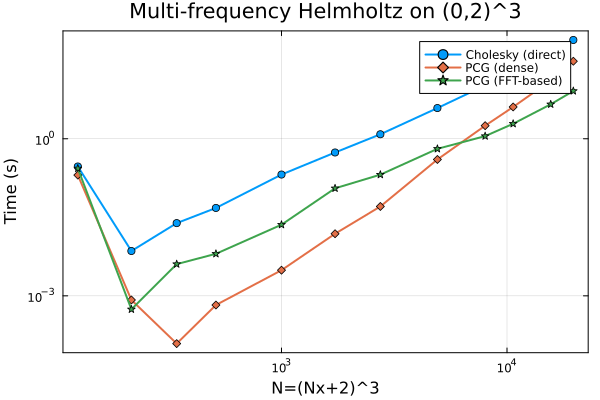

"/Users/shoji/Project_with_Jon/Helmholtz_high_freq/helmholtz3d_multifrequency_domain02_three_solver_timing.png"

In [6]:
# ============================================================
# Timing comparison: Cholesky / PCG dense / PCG FFT-based
# ============================================================

Ns = [r.N for r in results]
t_direct = [r.t_direct for r in results]
t_pcg_dense = [r.t_pcg_dense for r in results]
t_pcg_fft = [r.t_pcg_fft for r in results]

mask_chol = .!isnan.(t_direct)
mask_dense = .!isnan.(t_pcg_dense)

p_time = plot(
    Ns[mask_chol], t_direct[mask_chol];
    marker=:circle, lw=2,
    label="Cholesky (direct)",
    xlabel="N=(Nx+2)^3",
    ylabel="Time (s)",
    xscale=:log10,
    yscale=:log10,
    title="Multi-frequency Helmholtz on (0,2)^3",
    framestyle=:box
)

plot!(
    p_time,
    Ns[mask_dense], t_pcg_dense[mask_dense];
    marker=:diamond, lw=2,
    label="PCG (dense)"
)

plot!(
    p_time,
    Ns, t_pcg_fft;
    marker=:star5, lw=2,
    label="PCG (FFT-based)"
)

display(p_time)
savefig(p_time, "helmholtz3d_multifrequency_domain02_three_solver_timing.png")


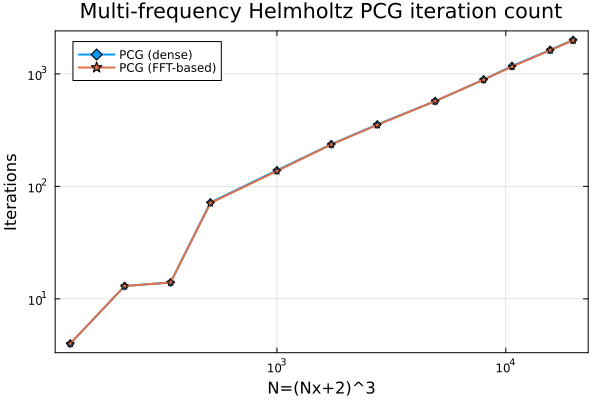

"/Users/shoji/Project_with_Jon/Helmholtz_high_freq/helmholtz3d_multifrequency_domain02_three_solver_iterations.png"

In [7]:
# ============================================================
# PCG iteration counts
# Cholesky is direct, so it has no iteration count.
# ============================================================

Ns = [r.N for r in results]
it_pcg_dense = [r.n_iter_pcg_dense for r in results]
it_pcg_fft = [r.n_iter_pcg_fft for r in results]
mask_dense = it_pcg_dense .>= 0

p_iter = plot(
    Ns[mask_dense], it_pcg_dense[mask_dense];
    marker=:diamond, lw=2,
    label="PCG (dense)",
    xlabel="N=(Nx+2)^3",
    ylabel="Iterations",
    xscale=:log10,
    yscale=:log10,
    title="Multi-frequency Helmholtz PCG iteration count",
    framestyle=:box
)

plot!(
    p_iter,
    Ns, it_pcg_fft;
    marker=:star5, lw=2,
    label="PCG (FFT-based)"
)

display(p_iter)
savefig(p_iter, "helmholtz3d_multifrequency_domain02_three_solver_iterations.png")
